# Vision-Based Gesture-to-Speech Translation for Sign Language

Python version: 3.12.6
Downloading dependencies.

In [1]:
%load_ext autoreload
%autoreload 2

%pip install torch torchvision kagglehub opencv-python tensorflow tensorflow.keras

# pytorch
import torch

# kaggle (for downloading datasets) and dataset manage
import kagglehub as kh
import os

Note: you may need to restart the kernel to use updated packages.


In [2]:
# dataset download
lis_path = kh.dataset_download("nicholasnisopoli/lisdataset")
asl_path = kh.dataset_download("grassknoted/asl-alphabet")
print("Italian Sing Language dataset path:", lis_path)
print("American Sign Language dataset path:", asl_path)
lis_dataset = os.path.join(lis_path, "LIS-fingerspelling-dataset")
asl_dataset = os.path.join(asl_path, "asl_alphabet_train/asl_alphabet_train")

Italian Sing Language dataset path: /Users/anna/.cache/kagglehub/datasets/nicholasnisopoli/lisdataset/versions/1
American Sign Language dataset path: /Users/anna/.cache/kagglehub/datasets/grassknoted/asl-alphabet/versions/1


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## LIS model

In [4]:
from train import train_and_save
from plotter import plot_loss, plot_acc

from dataclasses import dataclass

@dataclass
class TrainConfig:
    train_threshold: float = 0.85
    epochs: int = 25
    batch_size: int = 32
    learning_rate: float = 0.01
    
    
config = TrainConfig()

Epoch 01/25 | train_loss=3.0892, train_acc=0.0517 | test_loss=3.0809, test_acc=0.0983
Epoch 02/25 | train_loss=3.0790, train_acc=0.0682 | test_loss=3.0645, test_acc=0.1044
Epoch 03/25 | train_loss=3.0566, train_acc=0.0948 | test_loss=3.0148, test_acc=0.1627
Epoch 04/25 | train_loss=2.9558, train_acc=0.1319 | test_loss=2.7033, test_acc=0.3081
Epoch 05/25 | train_loss=2.6402, train_acc=0.1908 | test_loss=2.1985, test_acc=0.2999
Epoch 06/25 | train_loss=2.3113, train_acc=0.2812 | test_loss=1.8281, test_acc=0.4473
Epoch 07/25 | train_loss=2.0126, train_acc=0.3541 | test_loss=1.6019, test_acc=0.4514
Epoch 08/25 | train_loss=1.7315, train_acc=0.4324 | test_loss=1.1518, test_acc=0.6366
Epoch 09/25 | train_loss=1.5049, train_acc=0.5049 | test_loss=0.9664, test_acc=0.7103
Epoch 10/25 | train_loss=1.3585, train_acc=0.5474 | test_loss=0.9112, test_acc=0.6510
Epoch 11/25 | train_loss=1.2093, train_acc=0.5823 | test_loss=0.9124, test_acc=0.6602
Epoch 12/25 | train_loss=1.0911, train_acc=0.6250 | te

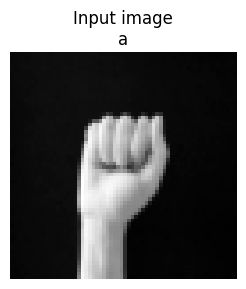

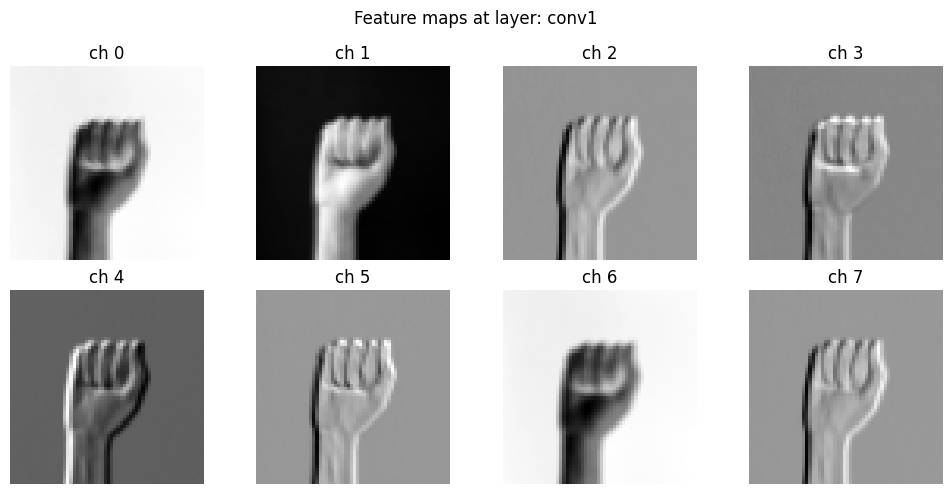

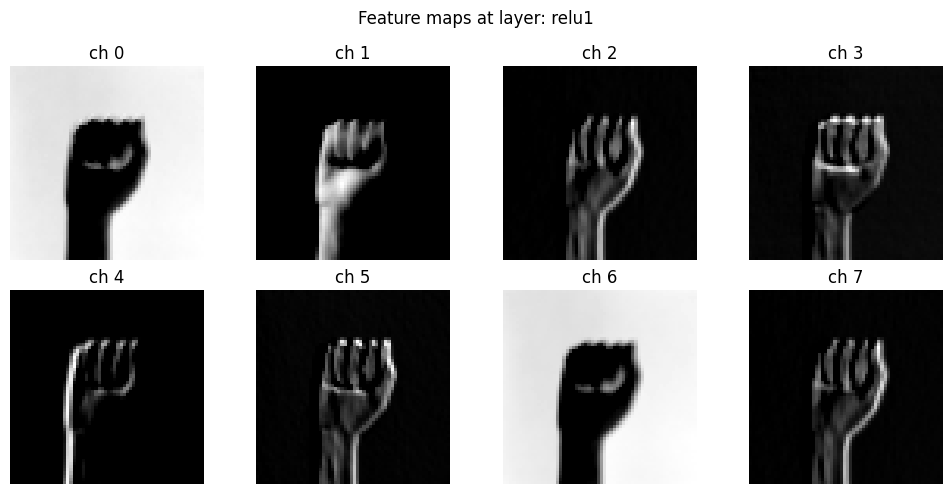

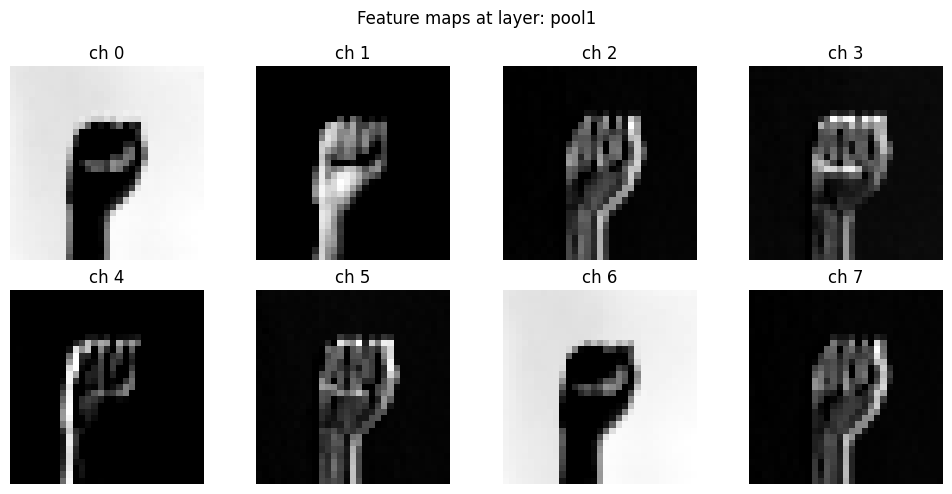

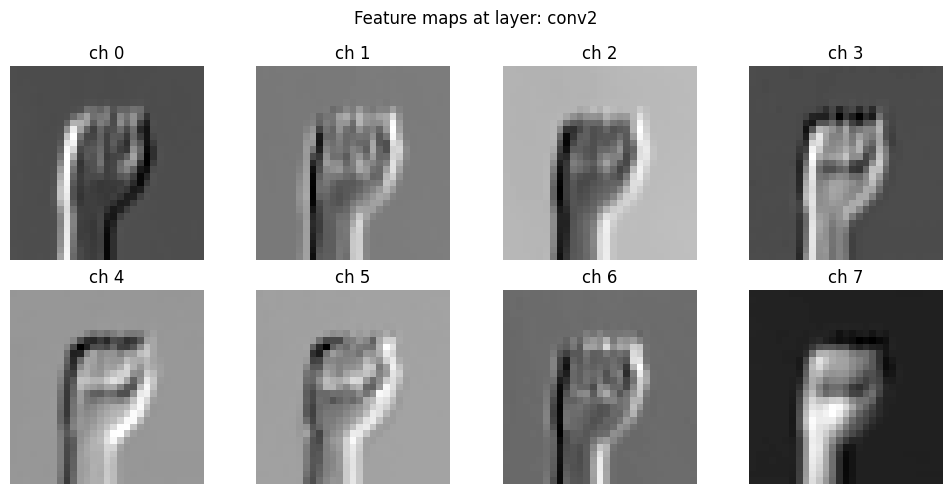

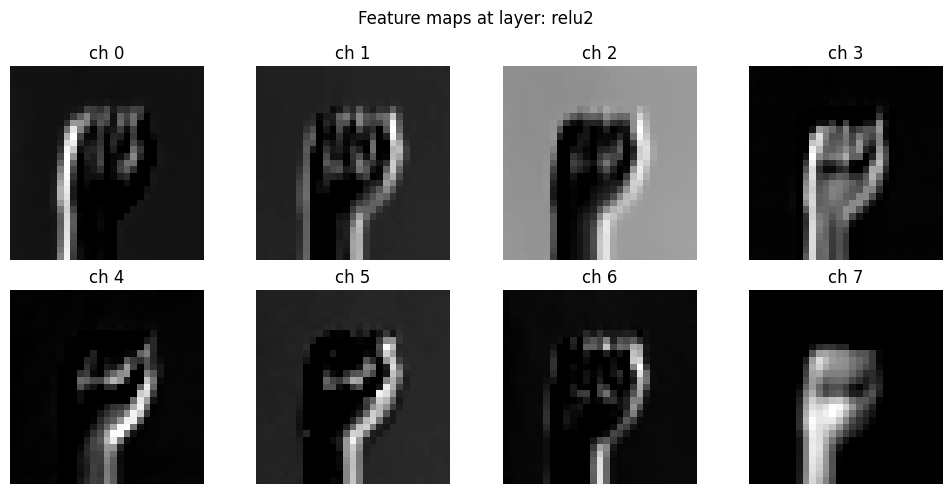

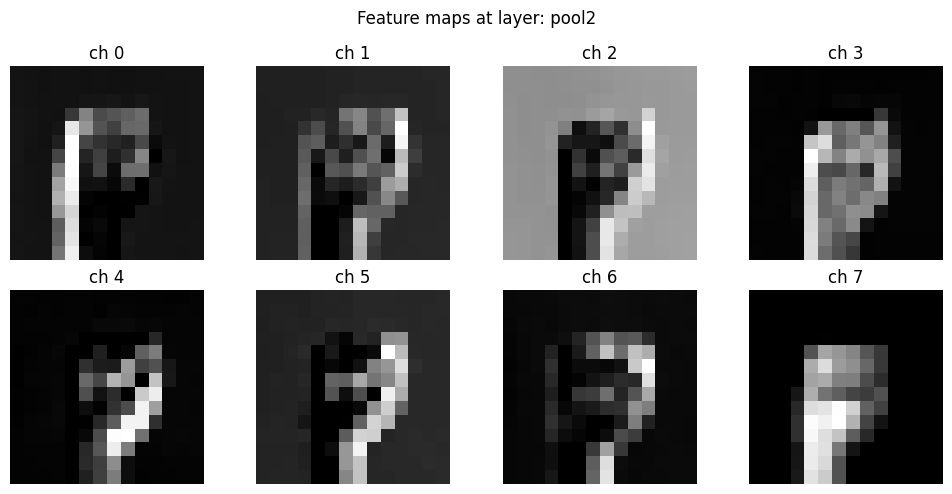

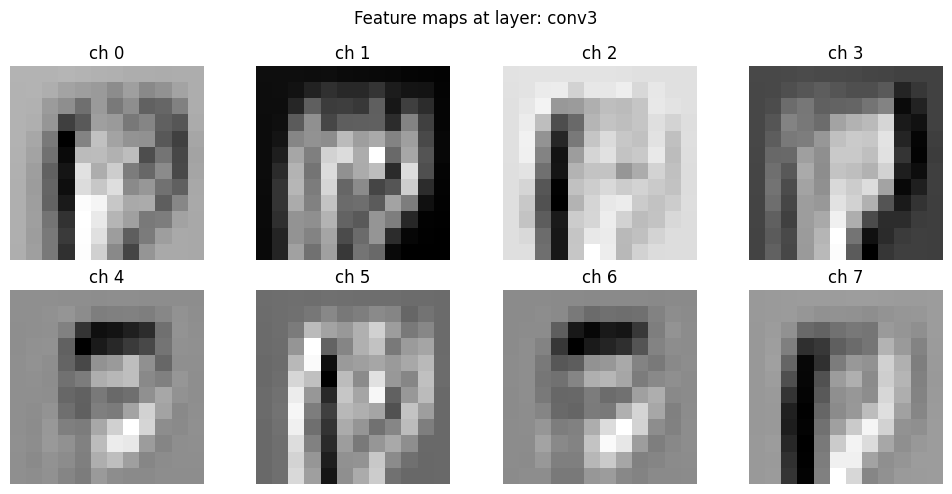

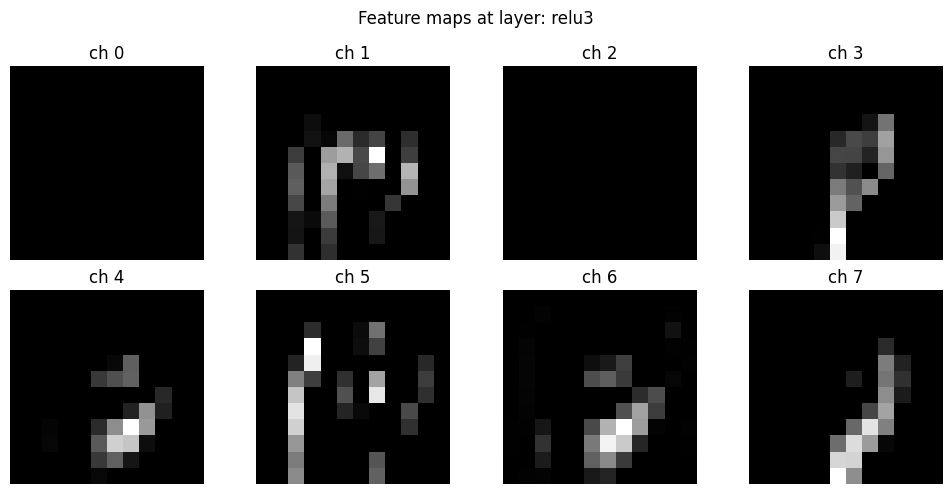

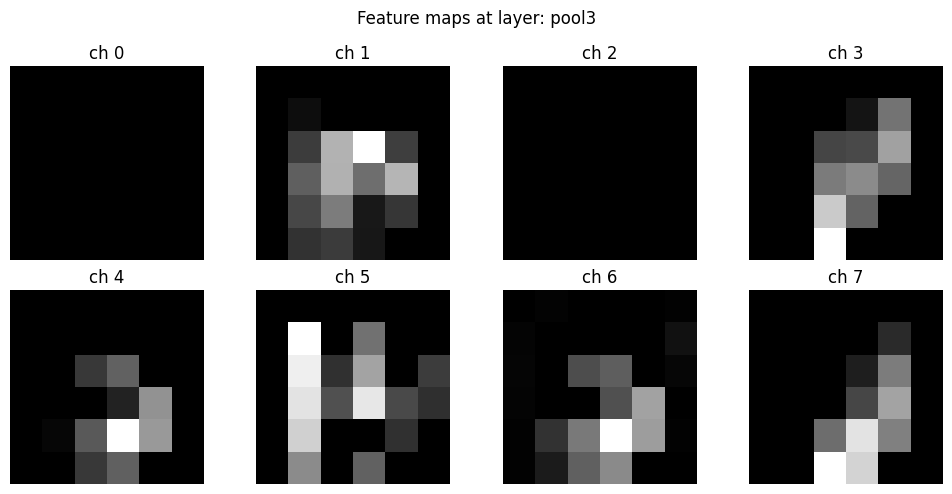

ValueError: too many values to unpack (expected 2)

In [5]:
from model import SignLanguageCNN
path_params = "lis_model.pth"

# If you want to save the paramenters, change output_path with path_params
lis_history = train_and_save(dataset=lis_dataset, model_class=SignLanguageCNN, config=config, device=device, output_path=path_params, save_repr=True)

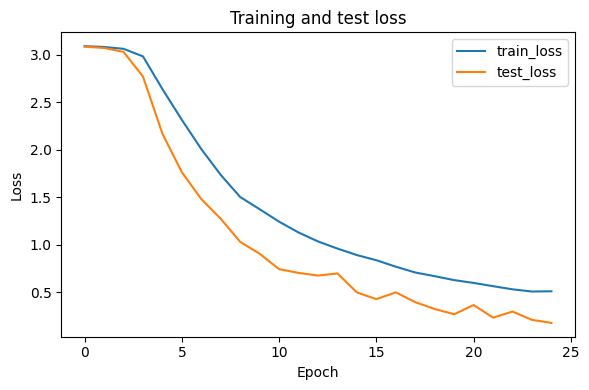

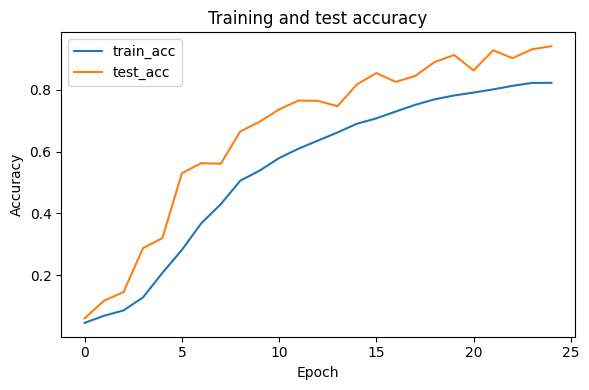

In [12]:
plot_loss(lis_history, "lis_cnn")
plot_acc(lis_history, "lis_cnn")

## ASL model

In [9]:
path_params = "asl_model.pth"

# If you want to save the paramenters, change output_path with path_params
asl_history = train_and_save(dataset=asl_dataset, model_class=SignLanguageCNN, config=config, device=device, output_path=path_params)

Epoch 01/25 | train_loss=3.0773, train_acc=0.1203 | test_loss=2.1859, test_acc=0.3698
Epoch 02/25 | train_loss=1.9345, train_acc=0.3940 | test_loss=1.0149, test_acc=0.6857
Epoch 03/25 | train_loss=1.2406, train_acc=0.5911 | test_loss=0.5707, test_acc=0.8374
Epoch 04/25 | train_loss=0.8983, train_acc=0.7001 | test_loss=0.3498, test_acc=0.9034
Epoch 05/25 | train_loss=0.7074, train_acc=0.7610 | test_loss=0.2499, test_acc=0.9330
Epoch 06/25 | train_loss=0.5775, train_acc=0.8043 | test_loss=0.1855, test_acc=0.9510
Epoch 07/25 | train_loss=0.4886, train_acc=0.8340 | test_loss=0.1414, test_acc=0.9647
Epoch 08/25 | train_loss=0.4209, train_acc=0.8561 | test_loss=0.0931, test_acc=0.9766
Epoch 09/25 | train_loss=0.3714, train_acc=0.8734 | test_loss=0.0811, test_acc=0.9811
Epoch 10/25 | train_loss=0.3305, train_acc=0.8873 | test_loss=0.0652, test_acc=0.9836
Epoch 11/25 | train_loss=0.3013, train_acc=0.8978 | test_loss=0.0626, test_acc=0.9833
Epoch 12/25 | train_loss=0.2741, train_acc=0.9075 | te

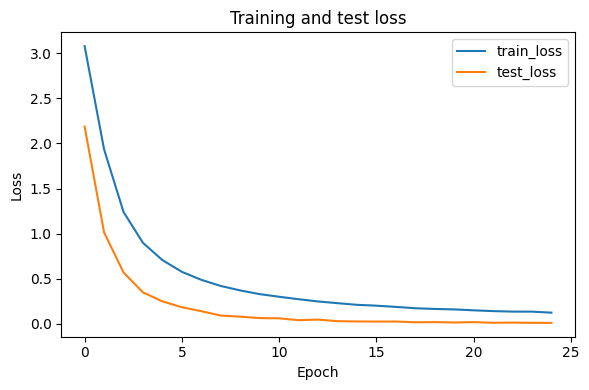

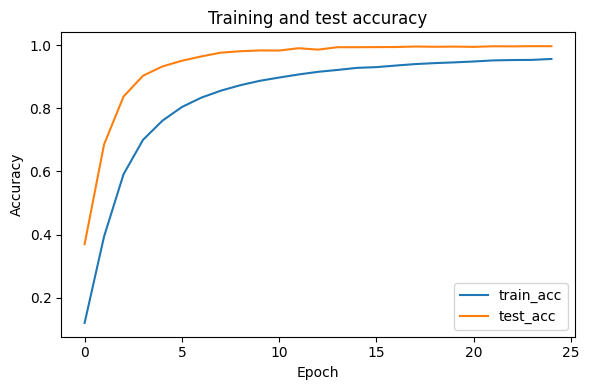

In [11]:
plot_loss(asl_history, "asl_cnn")
plot_acc(asl_history, "asl_cnn")

## ResNET50

In [13]:
from torchvision.models import resnet50
path_params = "LIS_resnet50_model.pth"

# If you want to save the parameters, change output_path with path_params
resnet_history_LIS = train_and_save(dataset=lis_dataset, model_class=resnet50, config=config, device=device, output_path=path_params)

Epoch 01/25 | train_loss=3.0362, train_acc=0.1277 | test_loss=2.9573, test_acc=0.2426


KeyboardInterrupt: 

In [ ]:
plot_loss(resnet_history_LIS)
plot_acc(resnet_history_LIS)

In [ ]:
path_params = "models/ASL_resnet50_model.pth"

# If you want to save the parameters, change output_path with path_params
resnet_history_ASL = train_and_save(dataset=asl_dataset, model_class=resnet50, config=config, device=device, output_path=path_params)

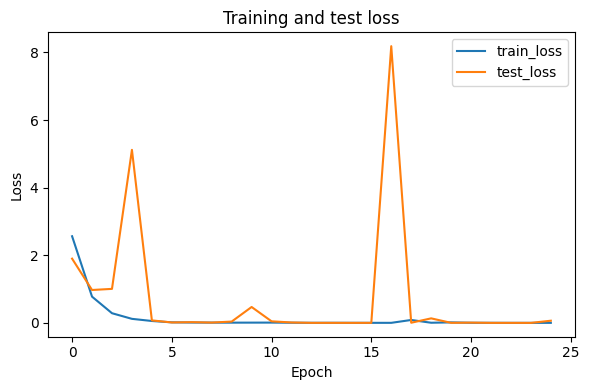

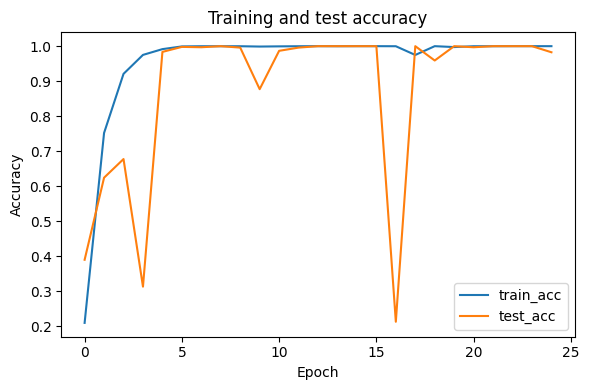

In [ ]:
plot_loss(resnet_history_ASL)
plot_acc(resnet_history_ASL)

## VGG16

In [ ]:
from torchvision.models import vgg16
path_params = "models/LIS_vgg16_model.pth"

# If you want to save the parameters, change output_path with path_params
vgg16_history_LIS = train_and_save(dataset=lis_dataset, model_class=vgg16, config=config, device=device, output_path=path_params)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /home/michelangelo/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:45<00:00, 12.0MB/s] 


KeyboardInterrupt: 

In [ ]:
plot_loss(vgg16_history_LIS)
plot_acc(vgg16_history_LIS)

In [ ]:
path_params = "models/ASL_vgg16_model.pth"

# If you want to save the parameters, change output_path with path_params
vgg16_history_ASL = train_and_save(dataset=lis_dataset, model_class=vgg16, config=config, device=device, output_path=path_params)

In [ ]:
plot_loss(vgg16_history_ASL)
plot_acc(vgg16_history_ASL)

## MobileNetV2

In [ ]:
#from mobilenetv2 import MobileNetV2
#lis_history = train_and_save(dataset=lis_dataset, model_class=MobileNetV2, config=config, device=device, output_path="mnv2_lis_model.pth")

from torchvision.models import mobilenet_v2
path_params = "models/LIS_mobilenetv2_model.pth"

# If you want to save the parameters, change output_path with path_params
mobilenetv2_history_LIS = train_and_save(dataset=lis_dataset, model_class=mobilenet_v2, config=config, device=device, output_path=path_params)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /home/michelangelo/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:01<00:00, 9.53MB/s]


KeyboardInterrupt: 

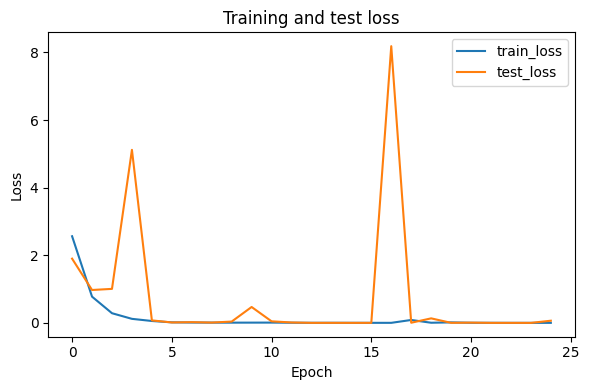

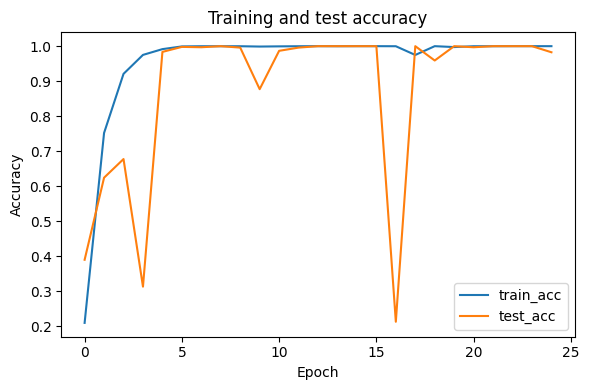

In [ ]:
plot_loss(mobilenetv2_history_LIS)
plot_acc(mobilenetv2_history_LIS)

In [ ]:
path_params = "models/ASL_mobilenetv2_model.pth"

# If you want to save the parameters, change output_path with path_params
mobilenetv2_history_ASL = train_and_save(dataset=asl_dataset, model_class=mobilenet_v2, config=config, device=device, output_path=path_params)

In [ ]:
plot_loss(mobilenetv2_history_ASL)
plot_acc(mobilenetv2_history_ASL)

## Test


In [3]:
from testing import test_camera

lis_idx_to_string = {0: 'a', 1: 'b', 2: 'c', 3: 'd', 4: 'e', 5: 'f', 6: 'h', 7: 'i', 8: 'k', 9: 'l', 10: 'm', 11: 'n', 12: 'o', 13: 'p', 14: 'q', 15: 'r', 16: 't', 17: 'u', 18: 'v', 19: 'w', 20: 'x', 21: 'y'}
asl_idx_to_string = {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E', 5: 'F', 6: 'G', 7: 'H', 8: 'I', 9: 'J', 10: 'K', 11: 'L', 12: 'M', 13: 'N', 14: 'O', 15: 'P', 16: 'Q', 17: 'R', 18: 'S', 19: 'T', 20: 'U', 21: 'V', 22: 'W', 23: 'X', 24: 'Y', 25: 'Z', 26: 'del', 27: 'nothing', 28: 'space'}


### LIS test with our model

In [ ]:
from model import SignLanguageCNN
test_camera(SignLanguageCNN, "lis_model.pth", lis_idx_to_string)

I0000 00:00:1783012900.244280 12667685 gl_context.cc:407] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3
W0000 00:00:1783012900.247999 12667692 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1783012900.251904 12667693 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


### ASL test with our model

In [ ]:
from model import SignLanguageCNN
test_camera(SignLanguageCNN, "asl_model.pth", asl_idx_to_string)

I0000 00:00:1783013641.794395 12723707 init-domain.cc:128] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
I0000 00:00:1783013641.848285 12723707 gl_context.cc:407] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1783013641.856736 12723710 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1783013641.866358 12723710 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1783013641.915708 12723709 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.
E0000 00:00:1783013788.449491 12723708 portable_clearcut_uploader.cc:90] Failed to send to clearcut: FAILED_PRECONDITIO

: 

### LIS test with Resnet

In [ ]:
from ResNet import ResNet50
test_camera(ResNet50, "resnet_lis_model", lis_idx_to_string)

### LIS test with MNV2

In [ ]:
from mobilenetv2 import MobileNetV2
test_camera(MobileNetV2, "mnv2_lis_model.pth", lis_idx_to_string)

I0000 00:00:1783013346.304868 12703985 init-domain.cc:128] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
I0000 00:00:1783013346.351654 12703985 gl_context.cc:407] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1783013346.357571 12703991 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1783013346.366586 12703993 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1783013346.402845 12703992 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.
E0000 00:00:1783013466.340415 12703986 portable_clearcut_uploader.cc:90] Failed to send to clearcut: INTERNAL: Response

: 